In [1]:

!pip install -q kagglehub tensorflow scikit-learn pandas numpy matplotlib seaborn


In [4]:

import os
import glob
import random
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import kagglehub

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)


TensorFlow version: 2.21.0
GPU available: True


In [5]:

dataset_path = kagglehub.dataset_download(
    "bertvankeulen/cicids-2017"
)

print("Dataset downloaded to:", dataset_path)

csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(os.path.basename(file))


Using Colab cache for faster access to the 'cicids-2017' dataset.
Dataset downloaded to: /kaggle/input/cicids-2017
Number of CSV files: 10
wednesday_plus.csv
thursday_plus.csv
friday_plus.csv
tuesday.csv
monday.csv
friday.csv
wednesday.csv
thursday.csv
tuesday_plus.csv
monday_plus.csv


In [6]:

dataframes = []

for file in csv_files:
    print("Loading:", os.path.basename(file))

    df = pd.read_csv(file, low_memory=False)

    df.columns = df.columns.str.strip()
    df = df.loc[:, ~df.columns.duplicated()]

    if "Label" not in df.columns:
        print("Skipping file without Label column")
        continue

    if len(df) > 15000:
        df = df.sample(
            n=15000,
            random_state=SEED
        )

    dataframes.append(df)

data = pd.concat(
    dataframes,
    ignore_index=True
)

print("\nCombined dataset shape:", data.shape)
print("\nLabel distribution:")
print(data["Label"].value_counts().head(15))


Loading: wednesday_plus.csv
Loading: thursday_plus.csv
Loading: friday_plus.csv
Loading: tuesday.csv
Loading: monday.csv
Loading: friday.csv
Loading: wednesday.csv
Loading: thursday.csv
Loading: tuesday_plus.csv
Loading: monday_plus.csv

Combined dataset shape: (150000, 105)

Label distribution:
Label
BENIGN                                  118800
DoS Hulk                                  9326
Portscan                                  8608
Infiltration - Portscan                   5970
DDoS                                      5068
DoS GoldenEye                              452
FTP-Patator                                378
DoS Slowloris                              234
SSH-Patator                                232
DoS Slowhttptest - Attempted               216
Botnet - Attempted                         194
DoS Slowloris - Attempted                  124
Web Attack - Brute Force - Attempted       124
DoS Slowhttptest                           120
Web Attack - XSS - Attempted           

In [25]:

data = data[data["Label"].notna()].copy()

data["Label"] = (
    data["Label"]
    .astype(str)
    .str.strip()
    .str.upper()
)

y = (data["Label"] != "BENIGN").astype(int)

drop_columns = [
    "Label",
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp"
]

X = data.drop(columns=drop_columns, errors="ignore")

X = X.apply(pd.to_numeric, errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)

X = X.dropna(axis=1, how="all")
X = X.loc[:, X.nunique(dropna=True) > 1]

valid_rows = X.notna().any(axis=1)

X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

print("Feature matrix:", X.shape)
print("\nBinary class distribution:")
print(y.value_counts())



Feature matrix: (150000, 101)

Binary class distribution:
Label
0    118800
1     31200
Name: count, dtype: int64


In [26]:

class_0 = X[y == 0]
class_1 = X[y == 1]

samples_per_class = min(
    len(class_0),
    len(class_1),
    30000
)

if samples_per_class < 100:
    raise ValueError("Insufficient samples in one of the classes.")

balanced_0 = class_0.sample(
    n=samples_per_class,
    random_state=SEED
)

balanced_1 = class_1.sample(
    n=samples_per_class,
    random_state=SEED
)

X_balanced = pd.concat(
    [balanced_0, balanced_1],
    axis=0
)

y_balanced = pd.Series(
    [0] * samples_per_class +
    [1] * samples_per_class
)

# Shuffle both together
shuffle_idx = np.random.RandomState(SEED).permutation(
    len(X_balanced)
)

X_balanced = X_balanced.iloc[shuffle_idx].reset_index(drop=True)
y_balanced = y_balanced.iloc[shuffle_idx].reset_index(drop=True)

print("Balanced dataset shape:", X_balanced.shape)
print("\nClass distribution:")
print(y_balanced.value_counts())


Balanced dataset shape: (60000, 101)

Class distribution:
0    30000
1    30000
Name: count, dtype: int64


In [27]:

X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_balanced,
    y_balanced,
    test_size=0.20,
    random_state=SEED,
    stratify=y_balanced
)

# Convert labels to NumPy arrays
y_train = y_train.to_numpy().astype(np.float32)
y_test = y_test.to_numpy().astype(np.int32)

# Handle missing values
imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train_df)
X_test_imp = imputer.transform(X_test_df)

# Normalize features
scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train_imp)
X_test = scaler.transform(X_test_imp)

# Keep features within normalized range
X_train = np.clip(X_train, 0, 1).astype(np.float32)
X_test = np.clip(X_test, 0, 1).astype(np.float32)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)
print("Number of features:", X_train.shape[1])


Training samples: (48000, 101)
Testing samples: (12000, 101)
Number of features: 101


In [28]:

def build_model(input_features, seed=42):

    tf.keras.utils.set_random_seed(seed)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_features,)),

        tf.keras.layers.Dense(
            128,
            activation="relu"
        ),

        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3),

        tf.keras.layers.Dense(
            64,
            activation="relu"
        ),

        tf.keras.layers.Dropout(0.2),

        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


input_features = X_train.shape[1]

model = build_model(input_features)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=12,
    batch_size=512,
    callbacks=[early_stop],
    verbose=1
)

print("Original IDS model training completed.")


Epoch 1/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9551 - loss: 0.1232 - val_accuracy: 0.9604 - val_loss: 0.3410
Epoch 2/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9915 - loss: 0.0299 - val_accuracy: 0.9916 - val_loss: 0.1842
Epoch 3/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9943 - loss: 0.0199 - val_accuracy: 0.9943 - val_loss: 0.0994
Epoch 4/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9954 - loss: 0.0160 - val_accuracy: 0.9948 - val_loss: 0.0517
Epoch 5/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9967 - loss: 0.0122 - val_accuracy: 0.9952 - val_loss: 0.0266
Epoch 6/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9973 - loss: 0.0096 - val_accuracy: 0.9973 - val_loss: 0.0150
Epoch 7/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9974 - loss: 0.0087 - val_accuracy: 0.9971 - val_loss: 0.0095
Epoch 8/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9976 - loss: 0.0071 - val_accuracy: 0.9973 - val_loss

In [29]:

def get_predictions(model, X):
    probabilities = model.predict(
        X,
        verbose=0
    ).ravel()

    return (probabilities >= 0.5).astype(int)


def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred) * 100,
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ) * 100,
        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        ) * 100
    }


clean_predictions = get_predictions(
    model,
    X_test
)

clean_metrics = calculate_metrics(
    y_test,
    clean_predictions
)

print("Original Model - Clean Data")
print(classification_report(
    y_test,
    clean_predictions,
    target_names=["Benign", "Attack"],
    zero_division=0
))

print("Clean Accuracy:", round(clean_metrics["Accuracy"], 2), "%")


Original Model - Clean Data
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      6000
      Attack       1.00      1.00      1.00      6000

    accuracy                           1.00     12000
   macro avg       1.00      1.00      1.00     12000
weighted avg       1.00      1.00      1.00     12000

Clean Accuracy: 99.76 %


In [30]:

EPSILON = 0.10

def generate_fgsm(model, X, y, epsilon=0.10, batch_size=512):

    X_adv = X.copy()

    # Only attack malicious samples
    attack_indices = np.where(y == 1)[0]

    for start in range(0, len(attack_indices), batch_size):

        batch_indices = attack_indices[
            start:start + batch_size
        ]

        x_batch = tf.convert_to_tensor(
            X[batch_indices],
            dtype=tf.float32
        )

        with tf.GradientTape() as tape:

            tape.watch(x_batch)

            predictions = model(
                x_batch,
                training=False
            )

            # Target class: Benign (0)
            target_labels = tf.zeros_like(predictions)

            loss = tf.keras.losses.binary_crossentropy(
                target_labels,
                predictions
            )

            loss = tf.reduce_mean(loss)

        gradients = tape.gradient(
            loss,
            x_batch
        )

        # Targeted FGSM: move towards benign classification
        x_perturbed = (
            x_batch -
            epsilon * tf.sign(gradients)
        )

        x_perturbed = tf.clip_by_value(
            x_perturbed,
            0.0,
            1.0
        )

        X_adv[batch_indices] = x_perturbed.numpy()

    return X_adv


print("FGSM attack function created.")


FGSM attack function created.


In [31]:

X_adv_test = generate_fgsm(
    model,
    X_test,
    y_test,
    epsilon=EPSILON
)

adv_predictions = get_predictions(
    model,
    X_adv_test
)

adv_metrics = calculate_metrics(
    y_test,
    adv_predictions
)

# Percentage of malicious samples classified as benign
attack_success_rate = np.mean(
    adv_predictions[y_test == 1] == 0
) * 100

print("Original Model - Adversarial Data")
print("Accuracy:", round(adv_metrics["Accuracy"], 2), "%")
print("Precision:", round(adv_metrics["Precision"], 2), "%")
print("Recall:", round(adv_metrics["Recall"], 2), "%")
print("F1 Score:", round(adv_metrics["F1 Score"], 2), "%")
print("Attack Success Rate:", round(attack_success_rate, 2), "%")


Original Model - Adversarial Data
Accuracy: 49.91 %
Precision: 26.09 %
Recall: 0.1 %
F1 Score: 0.2 %
Attack Success Rate: 99.9 %


In [32]:

original_comparison = pd.DataFrame([
    {
        "Evaluation": "Clean Data",
        **clean_metrics
    },
    {
        "Evaluation": "FGSM Adversarial Data",
        **adv_metrics
    }
])

print(original_comparison.round(2).to_string(index=False))


           Evaluation  Accuracy  Precision  Recall  F1 Score
           Clean Data     99.76      99.72    99.8     99.76
FGSM Adversarial Data     49.91      26.09     0.1      0.20


In [33]:

X_adv_train = generate_fgsm(
    model,
    X_train,
    y_train,
    epsilon=EPSILON
)

# Combine clean and adversarial training samples
X_train_augmented = np.concatenate(
    [X_train, X_adv_train],
    axis=0
)

y_train_augmented = np.concatenate(
    [y_train, y_train],
    axis=0
)

print("Original training size:", len(X_train))
print("Augmented training size:", len(X_train_augmented))


Original training size: 48000
Augmented training size: 96000


In [34]:

adv_model = build_model(
    input_features,
    seed=123
)

adv_history = adv_model.fit(
    X_train_augmented,
    y_train_augmented,
    validation_split=0.2,
    epochs=12,
    batch_size=512,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

print("Adversarial training completed.")


Epoch 1/12
150/150 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9725 - loss: 0.0802 - val_accuracy: 0.9960 - val_loss: 0.1614
Epoch 2/12
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9953 - loss: 0.0171 - val_accuracy: 0.9986 - val_loss: 0.0326
Epoch 3/12
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9968 - loss: 0.0112 - val_accuracy: 0.9990 - val_loss: 0.0070
Epoch 4/12
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9977 - loss: 0.0079 - val_accuracy: 0.9991 - val_loss: 0.0032
Epoch 5/12
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9980 - loss: 0.0059 - val_accuracy: 0.9993 - val_loss: 0.0026
Epoch 6/12
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9983 - loss: 0.0049 - val_accuracy: 0.9992 - val_loss: 0.0023
Epoch 7/12
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9986 - loss: 0.0041 - val_accuracy: 0.9996 - val_loss: 0.0013
Epoch 8/12
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9987 - loss: 0.0040 - val_accuracy: 0.

In [35]:

adv_clean_predictions = get_predictions(
    adv_model,
    X_test
)

adv_defended_predictions = get_predictions(
    adv_model,
    X_adv_test
)

adv_training_clean_metrics = calculate_metrics(
    y_test,
    adv_clean_predictions
)

adv_training_attack_metrics = calculate_metrics(
    y_test,
    adv_defended_predictions
)

print("Adversarially Trained Model")

print("\nClean Data:")
print(adv_training_clean_metrics)

print("\nAdversarial Data:")
print(adv_training_attack_metrics)

adv_training_asr = np.mean(
    adv_defended_predictions[y_test == 1] == 0
) * 100

print("\nAttack Success Rate:", round(adv_training_asr, 2), "%")


Adversarially Trained Model

Clean Data:
{'Accuracy': 99.91666666666667, 'Precision': 99.94996664442962, 'Recall': 99.88333333333334, 'F1 Score': 99.91663887962655}

Adversarial Data:
{'Accuracy': 99.97500000000001, 'Precision': 99.95002498750625, 'Recall': 100.0, 'F1 Score': 99.9750062484379}

Attack Success Rate: 0.0 %


In [36]:

def feature_squeezing(X, decimals=1):
    return np.round(
        X,
        decimals=decimals
    ).astype(np.float32)


X_test_squeezed = feature_squeezing(
    X_test
)

X_adv_test_squeezed = feature_squeezing(
    X_adv_test
)

squeezed_clean_predictions = get_predictions(
    model,
    X_test_squeezed
)

squeezed_adv_predictions = get_predictions(
    model,
    X_adv_test_squeezed
)

squeezed_clean_metrics = calculate_metrics(
    y_test,
    squeezed_clean_predictions
)

squeezed_adv_metrics = calculate_metrics(
    y_test,
    squeezed_adv_predictions
)

squeezing_asr = np.mean(
    squeezed_adv_predictions[y_test == 1] == 0
) * 100

print("Feature Squeezing Defence")

print("\nClean Accuracy:",
      round(squeezed_clean_metrics["Accuracy"], 2), "%")

print("Adversarial Accuracy:",
      round(squeezed_adv_metrics["Accuracy"], 2), "%")

print("Attack Success Rate:",
      round(squeezing_asr, 2), "%")


Feature Squeezing Defence

Clean Accuracy: 99.76 %
Adversarial Accuracy: 49.92 %
Attack Success Rate: 99.85 %


In [37]:

second_model = build_model(
    input_features,
    seed=456
)

second_history = second_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=12,
    batch_size=512,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

print("Second model training completed.")


Epoch 1/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9501 - loss: 0.1286 - val_accuracy: 0.9302 - val_loss: 0.3816
Epoch 2/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9907 - loss: 0.0308 - val_accuracy: 0.9848 - val_loss: 0.2128
Epoch 3/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9938 - loss: 0.0213 - val_accuracy: 0.9957 - val_loss: 0.1103
Epoch 4/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9952 - loss: 0.0168 - val_accuracy: 0.9958 - val_loss: 0.0570
Epoch 5/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9964 - loss: 0.0125 - val_accuracy: 0.9968 - val_loss: 0.0266
Epoch 6/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9968 - loss: 0.0106 - val_accuracy: 0.9968 - val_loss: 0.0153
Epoch 7/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9973 - loss: 0.0092 - val_accuracy: 0.9969 - val_loss: 0.0118
Epoch 8/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9976 - loss: 0.0079 - val_accuracy: 0.9975 - val_loss

In [38]:

def ensemble_predict(model1, model2, X):

    pred1 = model1.predict(
        X,
        verbose=0
    ).ravel()

    pred2 = model2.predict(
        X,
        verbose=0
    ).ravel()

    average_predictions = (
        pred1 + pred2
    ) / 2

    return (
        average_predictions >= 0.5
    ).astype(int)


ensemble_clean_predictions = ensemble_predict(
    model,
    second_model,
    X_test
)

ensemble_adv_predictions = ensemble_predict(
    model,
    second_model,
    X_adv_test
)

ensemble_clean_metrics = calculate_metrics(
    y_test,
    ensemble_clean_predictions
)

ensemble_adv_metrics = calculate_metrics(
    y_test,
    ensemble_adv_predictions
)

ensemble_asr = np.mean(
    ensemble_adv_predictions[y_test == 1] == 0
) * 100

print("Ensemble Defence")

print("\nClean Accuracy:",
      round(ensemble_clean_metrics["Accuracy"], 2), "%")

print("Adversarial Accuracy:",
      round(ensemble_adv_metrics["Accuracy"], 2), "%")

print("Attack Success Rate:",
      round(ensemble_asr, 2), "%")


Ensemble Defence

Clean Accuracy: 99.8 %
Adversarial Accuracy: 49.97 %
Attack Success Rate: 99.78 %


In [39]:

results = []

def add_result(name, clean, adversarial, asr):

    results.append({
        "Model / Defence": name,
        "Clean Accuracy (%)": round(clean["Accuracy"], 2),
        "Adversarial Accuracy (%)": round(
            adversarial["Accuracy"], 2
        ),
        "Precision (%)": round(
            adversarial["Precision"], 2
        ),
        "Recall (%)": round(
            adversarial["Recall"], 2
        ),
        "F1 Score (%)": round(
            adversarial["F1 Score"], 2
        ),
        "Attack Success Rate (%)": round(asr, 2)
    })


add_result(
    "Original Model",
    clean_metrics,
    adv_metrics,
    attack_success_rate
)

add_result(
    "Adversarial Training",
    adv_training_clean_metrics,
    adv_training_attack_metrics,
    adv_training_asr
)

add_result(
    "Feature Squeezing",
    squeezed_clean_metrics,
    squeezed_adv_metrics,
    squeezing_asr
)

add_result(
    "Model Ensemble",
    ensemble_clean_metrics,
    ensemble_adv_metrics,
    ensemble_asr
)

results_df = pd.DataFrame(results)

print("\nFINAL DEFENCE COMPARISON\n")
print(results_df.to_string(index=False))

results_df.to_csv(
    "adversarial_defence_results.csv",
    index=False
)

print("\nResults saved successfully.")



FINAL DEFENCE COMPARISON

     Model / Defence  Clean Accuracy (%)  Adversarial Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  Attack Success Rate (%)
      Original Model               99.76                     49.91          26.09        0.10          0.20                    99.90
Adversarial Training               99.92                     99.98          99.95      100.00         99.98                     0.00
   Feature Squeezing               99.76                     49.92          32.14        0.15          0.30                    99.85
      Model Ensemble               99.80                     49.97          43.33        0.22          0.43                    99.78

Results saved successfully.


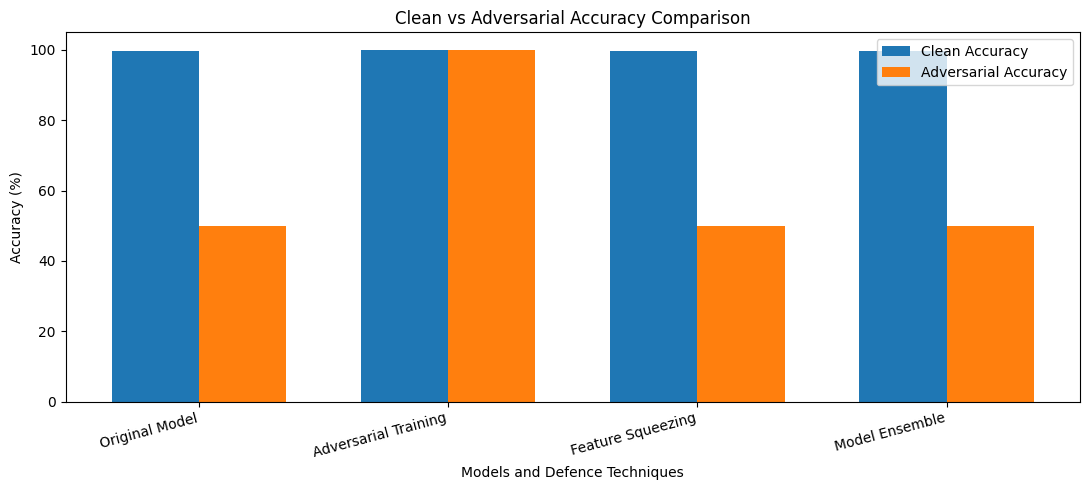

In [40]:

models = results_df["Model / Defence"]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(
    x - width/2,
    results_df["Clean Accuracy (%)"],
    width,
    label="Clean Accuracy"
)

plt.bar(
    x + width/2,
    results_df["Adversarial Accuracy (%)"],
    width,
    label="Adversarial Accuracy"
)

plt.xlabel("Models and Defence Techniques")
plt.ylabel("Accuracy (%)")
plt.title("Clean vs Adversarial Accuracy Comparison")

plt.xticks(
    x,
    models,
    rotation=15,
    ha="right"
)

plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()


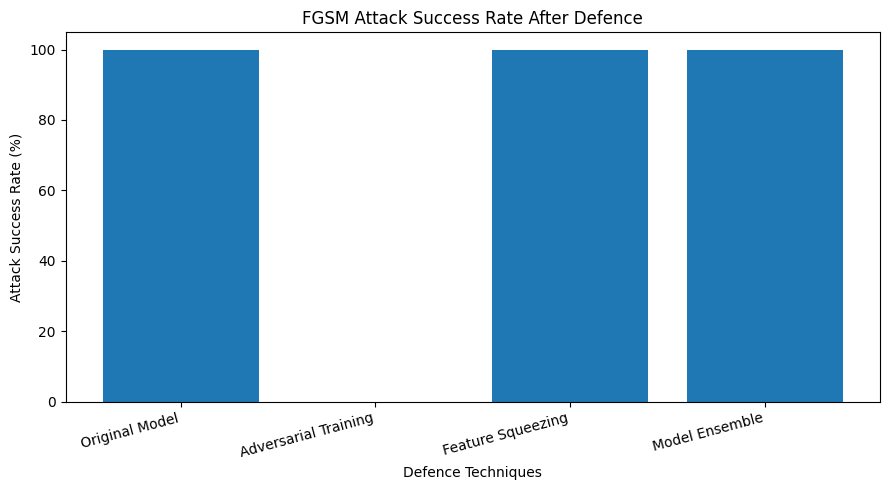

In [41]:

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model / Defence"],
    results_df["Attack Success Rate (%)"]
)

plt.xlabel("Defence Techniques")
plt.ylabel("Attack Success Rate (%)")
plt.title("FGSM Attack Success Rate After Defence")

plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


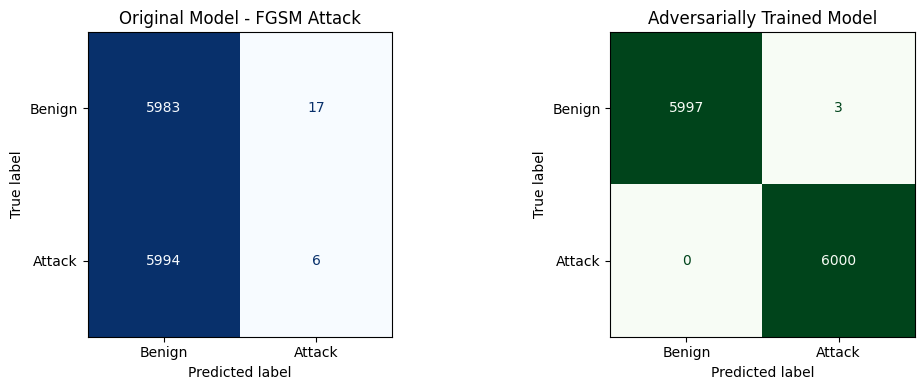

In [42]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

cm_original = confusion_matrix(
    y_test,
    adv_predictions
)

cm_defended = confusion_matrix(
    y_test,
    adv_defended_predictions
)

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm_original,
    display_labels=["Benign", "Attack"]
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("Original Model - FGSM Attack")

ConfusionMatrixDisplay(
    confusion_matrix=cm_defended,
    display_labels=["Benign", "Attack"]
).plot(
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)

axes[1].set_title("Adversarially Trained Model")

plt.tight_layout()
plt.show()
